# Chapter 1
### From simple to multiple regression

```python
from statsmodels.formula.api import ols
mdl_mass_vs_length = ols('mass_g ~ length_cm', data = fish).fit() # one intercept + one slope
mdl_mass_vs_species = ols('mass_g ~ species + 0', data = fish).fit() # 4 coefficients, one per category
mdl_mass_vs_both = ols('mass_g ~ length_cm + species + 0', data = fish).fit() # 1 slope, 1 intercept per category
print(mdl_mass_vs_length.params)
sns.regplot(
    x = 'length_cm', 
    y = 'mass_g',
    data = fish,
    ci = None)
sns.boxplot(
    x = 'species',
    y = 'mass_g',
    data = fish,
    showmeans = True)
coeffs = mdl_mass_vs_both.params
ic_bream, ic_perch, ic_pike, ic_roach, sl = coeffs
sns.scatterplot(
    x = 'length_cm',
    y = 'mass_g',
    hue = 'species',
    data = fish)
for ic_fish, color in zip([ic_bream, ic_perch, ic_pike, ic_roach],['blue','green','red','orange']):
    plt.axline(xy1 = (0, ic_fish), slope = sl, color = color)
```

In [1]:
import numpy as np 
np.select

x = np.arange(6)
condlist = [x<3, x>3]
choicelist = [x, x**2]
print(condlist, choicelist)
np.select(condlist, choicelist, 42)

[array([ True,  True,  True, False, False, False]), array([False, False, False, False,  True,  True])] [array([0, 1, 2, 3, 4, 5]), array([ 0,  1,  4,  9, 16, 25])]


array([ 0,  1,  2, 42, 16, 25])

In [2]:
a = [[True,False,False],[True,True,False]]
b = [[1,2,3],[4,5,6]]

np.select(a,b,999)

array([  1,   5, 999])

- making predictions using two coefficients (one of them is categorical - this is shocking for me!)

```python

# part 1: generating prediction workflow - custom categorical & numerical values for explanatory variables
from itertools import product
length_com = np.arange(5,61,5)
species = fish['species'].unique()
p = product(length_cm, species) # could be [(l, s) for l in length_cm for s in species]
expl_data_both = pd.DataFrame(p, columns = ['length_cm','species'])
# predicting mass_g from only length & from length & species
prediction_data_length = expl_data_length.assign(mass_g = mdl_mass_vs_length.predict(expl_data))
prediction_data_both = expl_data_both.assign(mass_g = mdl_mass_vs_both.predict(expl_data))

# visualizing predictions
for ic, color in zip([ic_bream, ic_perch, ic_pike, ic_roach],['blue green red orange'.split()]):
    plt.axline(xy1 = (0, ic), slope = sl, color = color)

    sns.scatterplot(
    x = 'length_cm', 
    y = 'mass_g',
    hue = 'species',
    data = fish)
sns.scatterplot(
    x = 'length_cm',
    y = 'mass_g',
    color = 'black',
    data = prediction_data)

continue...
```

-672.2418658971376 blue
-713.2928594927796 green
-1089.4560527593503 red
-726.7777988598328 orange


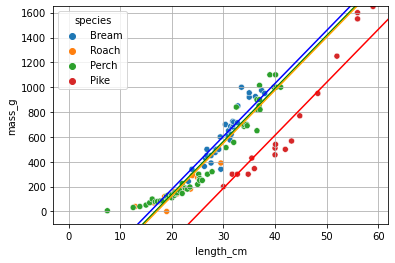

/home/user/.pyenv/versions/3.9.4/lib/python3.9/site-packages/seaborn/regression.py:592: UserWarning: legend_out is deprecated from the `lmplot` function signature. Please update your code to pass it using `facet_kws`.
  warnings.warn(msg, UserWarning)


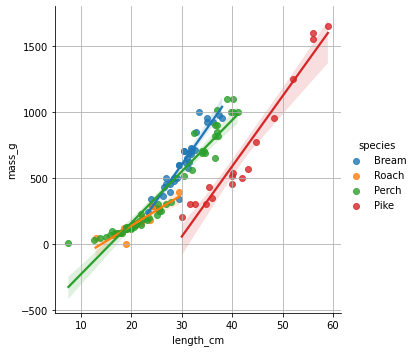

In [3]:
import pandas as pd
from statsmodels.formula.api import ols
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('fish.csv')

mdl = ols('mass_g ~ length_cm + species + 0', data = df).fit()

ic_bream, ic_perch, ic_pike, ic_roach, sl = mdl.params

for ic, color in zip([ic_bream, ic_perch, ic_pike, ic_roach],['blue','green','red','orange']):
    print(ic, color)
    plt.axline(xy1 = (0, ic), slope = sl, color = color)
sns.scatterplot(
    x = 'length_cm',
    y = 'mass_g',
    hue = 'species',
    data = df
)
sl
plt.ylim(-100, df['mass_g'].max())
plt.grid()
plt.show()

sns.lmplot(
    x = 'length_cm',
    y = 'mass_g',
    data = df,
    hue = 'species',
    legend_out = True
)
plt.grid()
plt.show()

<AxesSubplot:xlabel='length_cm', ylabel='mass_g'>

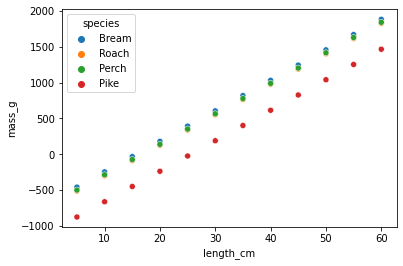

In [4]:
expl_data_both = pd.DataFrame(
    data = [[length, specie] for length in range(5,61,5) for specie in df['species'].unique()],
    columns = ['length_cm','species']
)

conditions = [expl_data_both['species'] == specie for specie in expl_data_both['species'].sort_values().unique()]
choices = [ic_bream, ic_perch, ic_pike, ic_roach]
intercept = np.select(conditions, choices)
prediction_data = expl_data_both.assign(intercept = intercept, mass_g = intercept + sl * expl_data_both['length_cm'])
prediction_data['mass_g_from_mdl'] = mdl.predict(expl_data_both)
prediction_data
sns.scatterplot(
x = 'length_cm',
    y = 'mass_g',
    hue = 'species',
    data = prediction_data
    )


#### Assessing model performance
- Coefficient of determination (R-squared)
  - larger is better
- Residual standard error (RSE):
  - smaller is better
  
```python
print(mdl_mass_vs_length.rsquared)
print(mdl_mass_vs_species.rsquared)
print(mdl_mass_vs_both.rsquared) # best result - but is that good?
```

- Adjusted Coefficient of Determination
  - too many explanatory variables causes overfitting
  - Adjusted coef of determination penalizes more explanatory variables
  - Ra2 = 1- (1-R2) * (n_obs - 1/)/(n_obs - n_var - 1)
  - in statsmodels:: rsquared_adj attribute
  
```python
print(mdl_mass_vs_both.rsquared)
print(mdl_mass_vs_both.rsquared_adj)
print(mdl_mass_vs_both.mse_resid)
rse_both = np.sqrt(mdl_mass_vs_both.mse_resid)
print(rse_both)
```
  


#### Specifying interactions

```python
# no interactions: response ~ explanatory1 + explanatory2
ols('mass_g ~ length_cm + species', data = df).fit() # one slope, 4 intercepts
# with interactions (implicit): response ~ explanatory1 * explanatory2
ols('mass_g ~ length_cm * species', data = df).fit() # mdl.params get ugly
# with interactions (explicit): response ~ explanatory1 + explanatory2 + explanatory1:explanatory2
ols('mass_g ~ length_cm + species + length_cm:species', data = df).fit() #mdl.params get perfect!
```

In [71]:
mdl_mass_vs_both_i = ols('mass_g ~ species + length_cm', data = df).fit() # 1 + 3 intercepts + 1 slope
mdl_mass_vs_both_i = ols('mass_g ~ species + length_cm + 0', data = df).fit() # 4 intercepts + 1 slope
mdl_mass_vs_both_i = ols('mass_g ~ species : length_cm', data = df).fit() # 1 intercept + 4 slopes
mdl_mass_vs_both_i = ols('mass_g ~ species : length_cm + 0', data = df).fit() # 4 slopes
mdl_mass_vs_both_i = ols('mass_g ~ species + species:length_cm', data = df).fit() # 1 + 3 intercepts+ 4 slopes
mdl_mass_vs_both_i = ols('mass_g ~ species + species:length_cm + 0', data = df).fit() # 4 intercepts+ 4 slopes
mdl_mass_vs_both_i = ols('mass_g ~ species + length_cm + species:length_cm', data = df).fit() # 1+3 intercepts + 1+3 slopes
mdl_mass_vs_both_i = ols('mass_g ~ species + length_cm + species:length_cm + 0', data = df).fit() # 4 intercepts + 1+3 slopes
mdl_mass_vs_both_i = ols('mass_g ~ species * length_cm', data = df).fit() # 1+3 intercepts + 1+3 slopes
mdl_mass_vs_both_i = ols('mass_g ~ species * length_cm + 0', data = df).fit() # 4 intercepts + 1+3 slopes
mdl_mass_vs_both_i = ols('mass_g ~ species + species * length_cm', data = df).fit() # 1+3 intercepts + 1+3 slopes
mdl_mass_vs_both_i = ols('mass_g ~ species + length_cm + species * length_cm + 0', data = df).fit() # 4 intercepts + 1+3 slopes
mdl_mass_vs_both_i = ols('mass_g ~ species + species * length_cm', data = df).fit() # 1+3 intercepts + 1+3 slopes
mdl_mass_vs_both_i = ols('mass_g ~ species + species * length_cm + 0', data = df).fit() # 4 intercepts + 1+3 slopes


mdl_mass_vs_both_i.params

species[Bream]               -1035.347565
species[Perch]                -619.175114
species[Pike]                -1540.824272
species[Roach]                -329.376211
length_cm                       54.549981
species[T.Perch]:length_cm     -15.638514
species[T.Pike]:length_cm       -1.355115
species[T.Roach]:length_cm     -31.230717
dtype: float64

In [72]:
mdl_mass_vs_both_i.predict()

array([ 230.21199261,  273.85197736,  268.39697927,  399.31693351,
        410.2269297 ,  426.59192398,  426.59192398,  470.23190873,
        470.23190873,  519.32689157,  513.87189348,  530.23688776,
        552.05688013,  573.8768725 ,  568.42187441,  568.42187441,
        622.97185535,  622.97185535,  650.24684581,  655.70184391,
        672.06683819,  677.52183628,  682.97683437,  699.34182865,
        704.79682675,  699.34182865,  710.25182484,  748.4368115 ,
        753.89180959,  792.07679624,  873.90176765,  873.90176765,
        939.36174477, 1004.82172189, 1037.55171045,  -28.55770182,
         55.39164957,   78.71091385,   95.03439884,  104.36210456,
        113.68981027,  116.02173669,  123.01751598,  146.33678025,
        148.66870668,  148.66870668,  160.32833882,  162.66026525,
        183.64760309,  183.64760309,  185.97952952,  220.95842594,
        230.28613165,  253.60539592,  358.54208517, -327.33911102,
       -132.78177545,  -82.1968682 ,  -35.50310767,   -8.26508

In [11]:
df.shape

(128, 3)